<a href="https://colab.research.google.com/github/KateYANG93/ExData_Plotting1/blob/master/Machine_Learning_in_Finance_Group_Work_Project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Category 1: Regularized Linear Regression (LASSO)


In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error

# S&P 500 ETF, 2020 to present
df = yf.download("SPY", start="2020-01-01",
                 auto_adjust=True,
                 multi_level_index=False,
                 progress=False)

In [ ]:
r = df["Close"].pct_change()

data = pd.DataFrame({
    "abs_return": r.abs(),
    "vol_5d": r.rolling(5).std(),
    "vol_20d": r.rolling(20).std(),
    "return_5d": df["Close"].pct_change(5),
    "volume_change": df["Volume"].pct_change(),
    "target": r.abs().shift(-1)
}).dropna()

X = data.drop(columns="target")
y = data["target"]

# 80% train, 20% test
n = int(len(X) * 0.8)
X_train, X_test = X.iloc[:n], X.iloc[n:]
y_train, y_test = y.iloc[:n], y.iloc[n:]

In [ ]:
alphas = np.logspace(-6, -2, 25)

search = GridSearchCV(
    make_pipeline(StandardScaler(), Lasso(max_iter=20000)),
    {"lasso__alpha": alphas},
    cv=TimeSeriesSplit(n_splits=5, gap=1),
    scoring="neg_mean_absolute_error"
)

search.fit(X_train, y_train)

model = search.best_estimator_
pred = np.maximum(model.predict(X_test), 0)

print("Best alpha:", search.best_params_)
print("Test MAE:", mean_absolute_error(y_test, pred))

Best alpha: {'lasso__alpha': np.float64(1e-06)}
Test MAE: 0.0037581039857856285


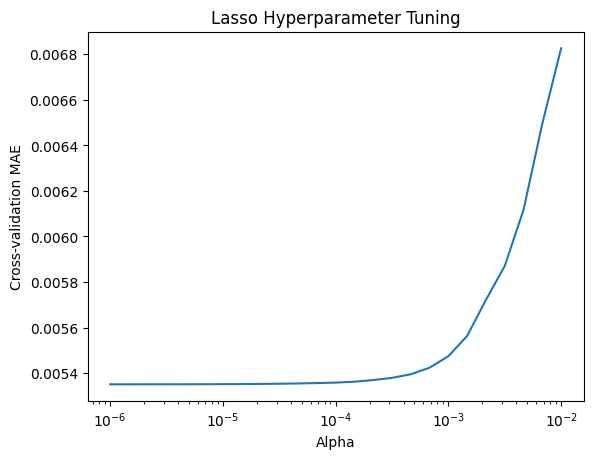

In [ ]:
plt.semilogx(alphas, -search.cv_results_["mean_test_score"])
plt.xlabel("Alpha")
plt.ylabel("Cross-validation MAE")
plt.title("Lasso Hyperparameter Tuning")
plt.show()

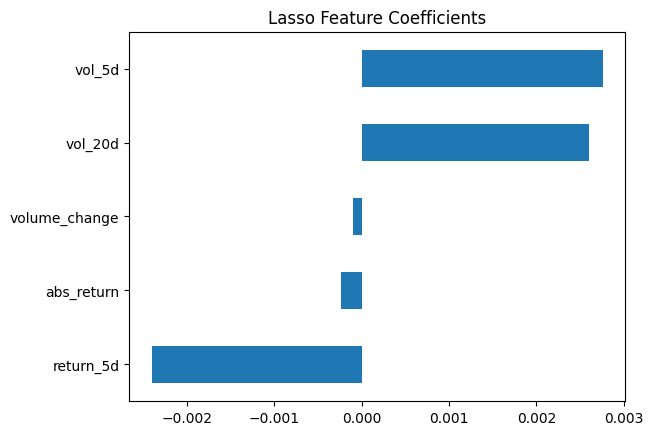

In [ ]:
coef = pd.Series(
    model.named_steps["lasso"].coef_,
    index=X.columns
)

coef.sort_values().plot.barh()
plt.title("Lasso Feature Coefficients")
plt.show()

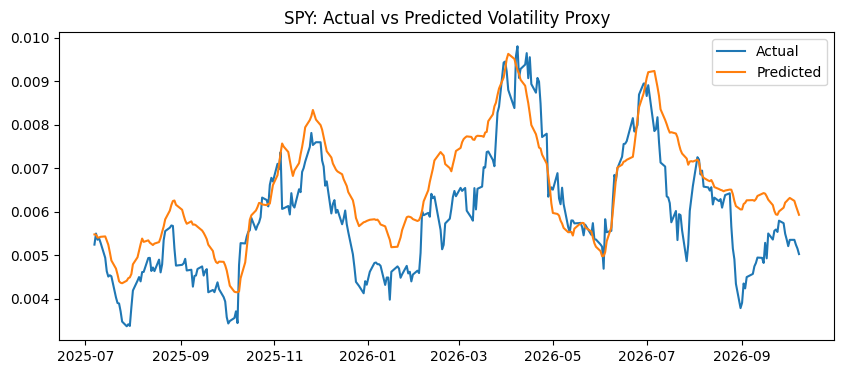

In [ ]:
actual = y_test.rolling(20).mean()
forecast = pd.Series(pred, index=y_test.index).rolling(20).mean()

plt.figure(figsize=(10, 4))
plt.plot(actual, label="Actual")
plt.plot(forecast, label="Predicted")
plt.legend()
plt.title("SPY: Actual vs Predicted Volatility Proxy")
plt.show()

In [ ]:
baseline = np.repeat(y_train.mean(), len(y_test))

print("Lasso MAE:", mean_absolute_error(y_test, pred))
print("Baseline MAE:", mean_absolute_error(y_test, baseline))

Lasso MAE: 0.0037581039857856285
Baseline MAE: 0.005076729277109797


# Category 4 : Classification Trees

In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import roc_auc_score, RocCurveDisplay

In [2]:
# Download daily QQQ prices since 2020
px = yf.download("QQQ",  start="2020-01-01", auto_adjust=True,
                 multi_level_index=False, progress=False)


r = px["Close"].pct_change()

# Construct features and target
df = pd.DataFrame({
    "abs_return": r.abs(),
    "volatility_5d": r.rolling(5).std(),
    "daily_range": (px["High"] - px["Low"]) / px["Close"],
    "volume_ratio": px["Volume"] / px["Volume"].rolling(10).mean(),
    "target": (r.shift(-1).abs() > 0.01).astype(int)
})

df = df.iloc[:-1].dropna()  # Remove last unknown target and initial NaNs
df.head()

,abs_return,volatility_5d,daily_range,volume_ratio,target
Date,,,,,
2020-01-15,0.000409,0.006862,0.007948,1.042010,0
2020-01-16,0.009583,0.007105,0.006838,0.800627,0
2020-01-17,0.004949,0.006393,0.006446,1.049927,0
2020-01-21,0.000448,0.005242,0.005285,0.914728,0
2020-01-22,0.002642,0.004030,0.006968,0.902474,0


In [3]:
# make sure the target is not too sparse
df['target'].describe()

,target
count,1692.000000
mean,0.417849
std,0.493351
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [4]:
X = df.drop(columns="target")
y = df["target"]

# Chronological 80/20 split
cut = int(len(df) * 0.80)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y.iloc[:cut], y.iloc[cut:]

# Hyperparameter tuning using time-series cross-validation
params = {
    "max_depth": [1, 2, 3, 4],
    "min_samples_leaf": [10, 25, 40]
}

search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    params,
    cv=TimeSeriesSplit(n_splits=5, gap=1),
    scoring="roc_auc"
)

search.fit(X_train, y_train)
model = search.best_estimator_

print("Best parameters:", search.best_params_)
print("Best CV AUC:", round(search.best_score_, 3))

Best parameters: {'max_depth': 3, 'min_samples_leaf': 25}
Best CV AUC: 0.576


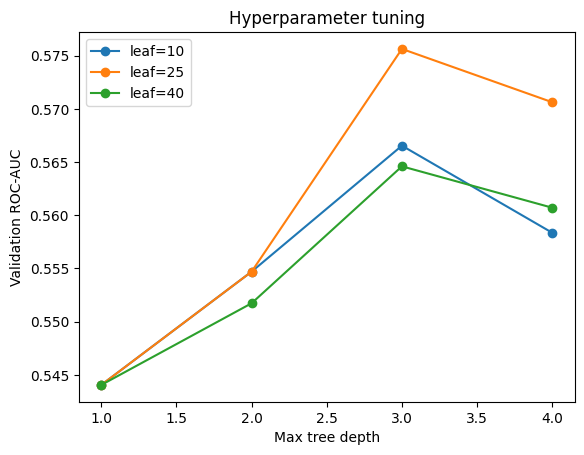

In [5]:
scores = pd.DataFrame(search.cv_results_)

for leaf in params["min_samples_leaf"]:
    s = scores[scores["param_min_samples_leaf"] == leaf]
    plt.plot(s["param_max_depth"].astype(int),
             s["mean_test_score"], "o-", label=f"leaf={leaf}")

plt.xlabel("Max tree depth")
plt.ylabel("Validation ROC-AUC")
plt.title("Hyperparameter tuning")
plt.legend()
plt.show()

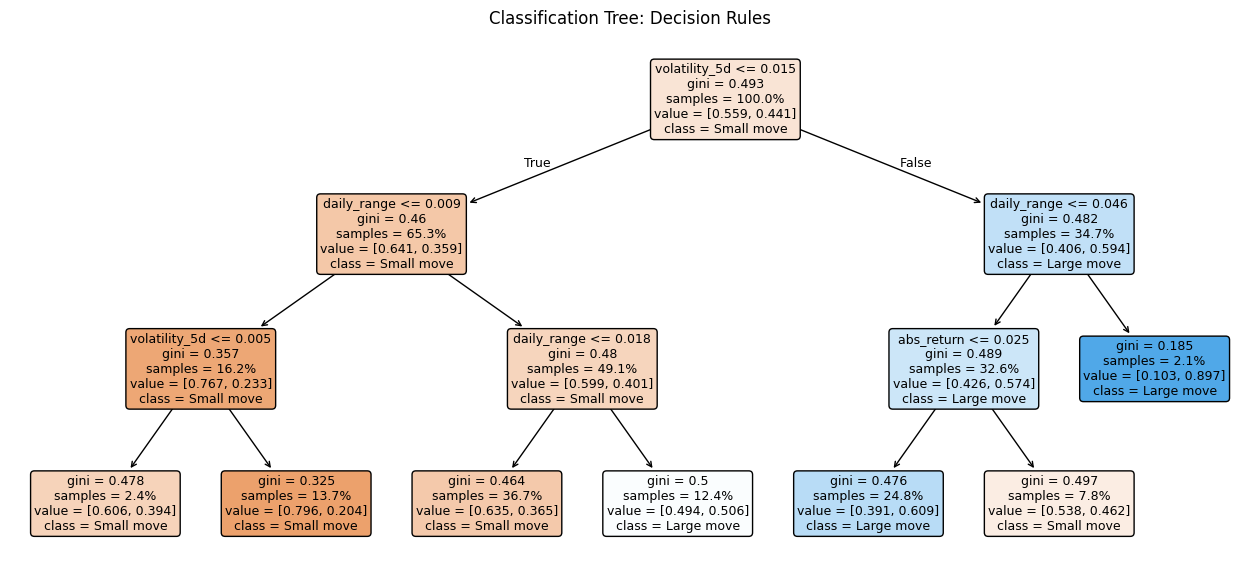

In [6]:
plt.figure(figsize=(16, 7))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Small move", "Large move"],
    filled=True,
    rounded=True,
    proportion=True,
    max_depth=3,
    fontsize=9
)

plt.title("Classification Tree: Decision Rules")
plt.show()

Test ROC-AUC: 0.567


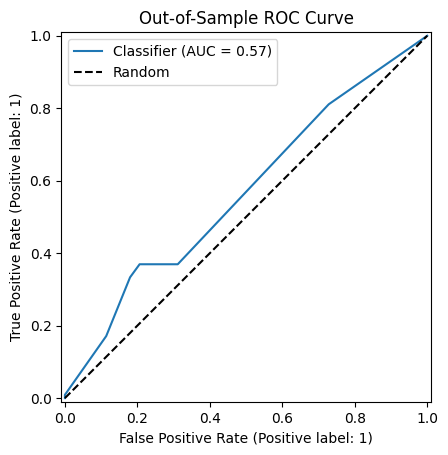

In [7]:
prob = model.predict_proba(X_test)[:, 1]

print("Test ROC-AUC:", round(roc_auc_score(y_test, prob), 3))

RocCurveDisplay.from_predictions(y_test, prob)
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.title("Out-of-Sample ROC Curve")
plt.legend()
plt.show()

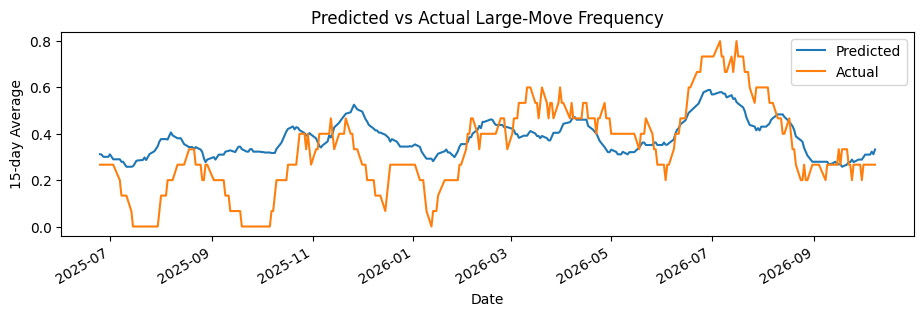

In [8]:
comparison = pd.DataFrame({
    "Predicted": prob,
    "Actual": y_test
}, index=y_test.index)

comparison.rolling(15).mean().plot(figsize=(11, 3))
plt.ylabel("15-day Average")
plt.title("Predicted vs Actual Large-Move Frequency")
plt.show()

### Now try to extend to random forest for comparison

In [10]:
from sklearn.ensemble import RandomForestClassifier

search_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    param_grid=params,       # Same grid as Decision Tree
    cv=search.cv,            # Same time-series CV
    scoring=search.scoring   # Same ROC-AUC metric
)

search_rf.fit(X_train, y_train)
rf = search_rf.best_estimator_
prob_rf = rf.predict_proba(X_test)[:, 1]

print("Best RF parameters:", search_rf.best_params_)
print("RF CV AUC:", round(search_rf.best_score_, 3))
print("Tree Test AUC:", round(roc_auc_score(y_test, prob), 3))
print("RF Test AUC:", round(roc_auc_score(y_test, prob_rf), 3))

Best RF parameters: {'max_depth': 3, 'min_samples_leaf': 10}
RF CV AUC: 0.577
Tree Test AUC: 0.567
RF Test AUC: 0.652


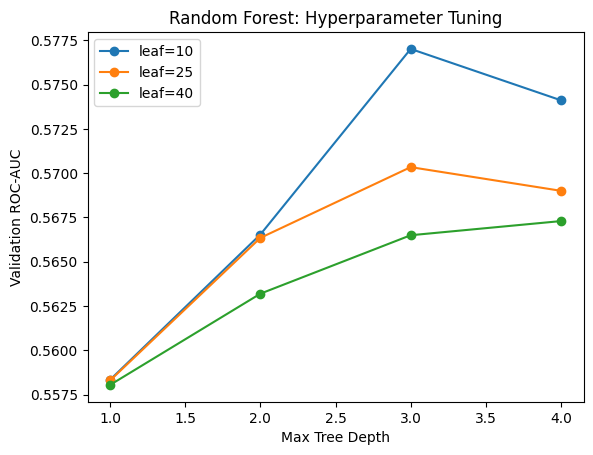

In [11]:
scores_rf = pd.DataFrame(search_rf.cv_results_)

for leaf in params["min_samples_leaf"]:
    s = scores_rf[scores_rf["param_min_samples_leaf"] == leaf]
    plt.plot(s["param_max_depth"].astype(int),
             s["mean_test_score"], "o-", label=f"leaf={leaf}")

plt.xlabel("Max Tree Depth")
plt.ylabel("Validation ROC-AUC")
plt.title("Random Forest: Hyperparameter Tuning")
plt.legend()
plt.show()

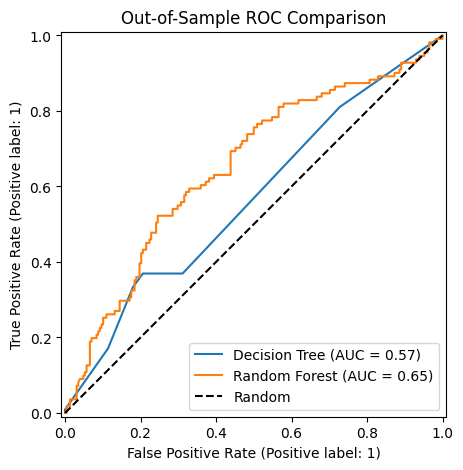

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(y_test, prob, name="Decision Tree", ax=ax)
RocCurveDisplay.from_predictions(y_test, prob_rf, name="Random Forest", ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Random")
ax.set_title("Out-of-Sample ROC Comparison")
ax.legend()
plt.show()

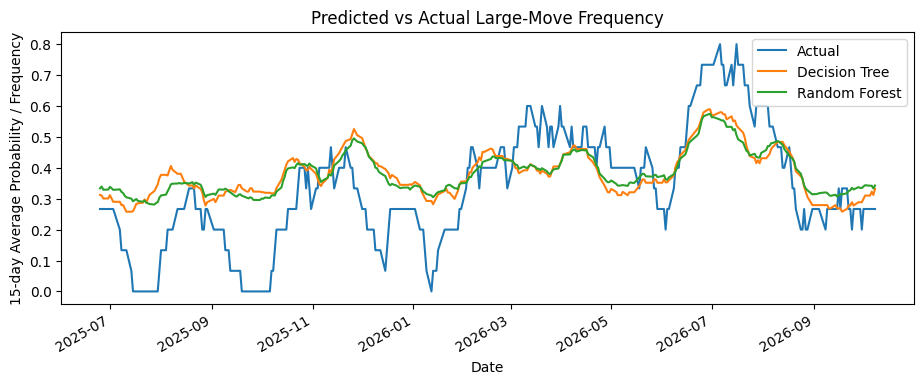

In [13]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Decision Tree": prob,
    "Random Forest": prob_rf
}, index=y_test.index)

comparison.rolling(15).mean().plot(figsize=(11, 4))

plt.ylabel("15-day Average Probability / Frequency")
plt.title("Predicted vs Actual Large-Move Frequency")
plt.show()

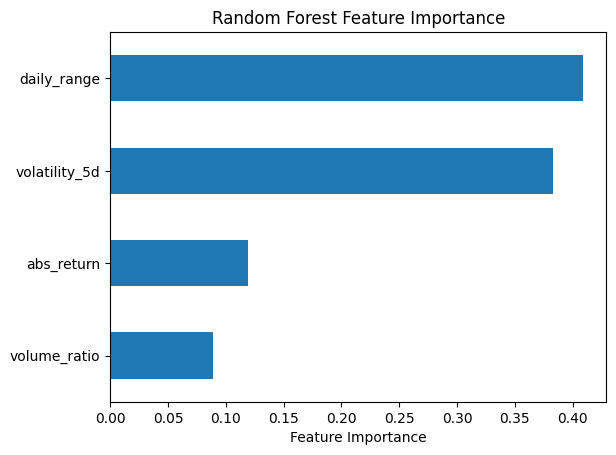

In [14]:
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot.barh()

plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.show()

# Category 3 : Principal components

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
np.random.seed(42)

n = 120

market = np.random.normal(0, 0.04, n)

data = pd.DataFrame({
    "S&P 500": market + np.random.normal(0, 0.015, n),
    "NASDAQ": 1.15 * market + np.random.normal(0, 0.018, n),
    "Dow Jones": 0.90 * market + np.random.normal(0, 0.014, n),
    "Russell 2000": 1.05 * market + np.random.normal(0, 0.025, n),
    "Emerging Markets": 0.75 * market + np.random.normal(0, 0.030, n)
})

data.head()

,S&P 500,NASDAQ,Dow Jones,Russell 2000,Emerging Markets
0,0.031734,0.008583,0.025153,0.017664,0.037611
1,-0.019171,-0.008425,0.016481,-0.029696,-0.031813
2,0.046949,0.038883,0.021794,-0.012958,0.045519
3,0.039893,0.085643,0.060453,0.069054,0.086360
4,-0.000563,-0.032376,0.001232,-0.028743,0.005378


In [ ]:
correlation_matrix = data.corr()

print(correlation_matrix)

                   S&P 500    NASDAQ  Dow Jones  Russell 2000  \
S&P 500           1.000000  0.883151   0.837181      0.801818   
NASDAQ            0.883151  1.000000   0.835071      0.803277   
Dow Jones         0.837181  0.835071   1.000000      0.778127   
Russell 2000      0.801818  0.803277   0.778127      1.000000   
Emerging Markets  0.626256  0.565770   0.590889      0.526615   

                  Emerging Markets  
S&P 500                   0.626256  
NASDAQ                    0.565770  
Dow Jones                 0.590889  
Russell 2000              0.526615  
Emerging Markets          1.000000  


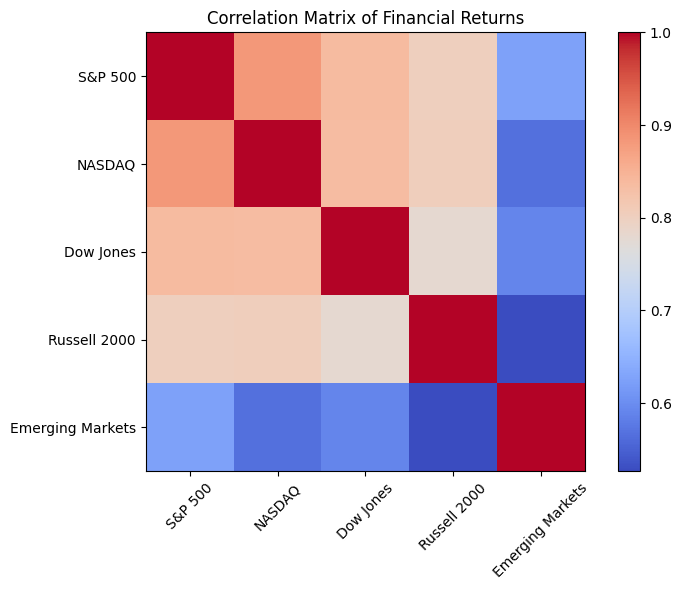

In [ ]:
plt.figure(figsize=(8, 6))

plt.imshow(correlation_matrix, cmap="coolwarm", interpolation="nearest")
plt.colorbar()

plt.xticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns, rotation=45)
plt.yticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns)

plt.title("Correlation Matrix of Financial Returns")
plt.tight_layout()
plt.show()

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(data)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=data.columns
)

X_scaled.head()

,S&P 500,NASDAQ,Dow Jones,Russell 2000,Emerging Markets
0,0.820174,0.275617,0.758897,0.535407,0.934505
1,-0.415608,-0.113440,0.516426,-0.506303,-0.696542
2,1.189544,0.968692,0.664992,-0.138153,1.120290
3,1.018252,2.038259,1.745938,1.665764,2.079813
4,0.036123,-0.661290,0.090066,-0.485355,0.177232


In [ ]:
pca = PCA()

principal_components = pca.fit_transform(X_scaled)

In [ ]:
pc_columns = [
    f"PC{i+1}" for i in range(principal_components.shape[1])
]

pc_data = pd.DataFrame(
    principal_components,
    columns=pc_columns
)

pc_data.head()

,PC1,PC2,PC3,PC4,PC5
0,1.456124,0.468611,-0.006105,0.178537,0.335752
1,-0.494904,-0.502487,-0.579438,0.579345,-0.158101
2,1.680269,0.651938,-0.788122,-0.431184,0.119780
3,3.765871,0.661387,0.162360,0.202898,-0.808259
4,-0.404908,0.430910,-0.253108,0.295493,0.461180


In [ ]:
explained_variance = pca.explained_variance_ratio_

explained_variance

array([0.78534089, 0.1104121 , 0.0459322 , 0.03570063, 0.02261417])

In [ ]:
cumulative_variance = np.cumsum(explained_variance)

variance_table = pd.DataFrame({
    "Principal Component": pc_columns,
    "Explained Variance": explained_variance,
    "Cumulative Variance": cumulative_variance
})

variance_table

,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.785341,0.785341
1,PC2,0.110412,0.895753
2,PC3,0.045932,0.941685
3,PC4,0.035701,0.977386
4,PC5,0.022614,1.000000


Interpretation:
PC1 explains 78.53% of the total variance, while PC1 and PC2
together explain 89.58%. Therefore, PCA substantially reduces
the dimensionality of the five financial variables while retaining
most of the information in the original dataset.

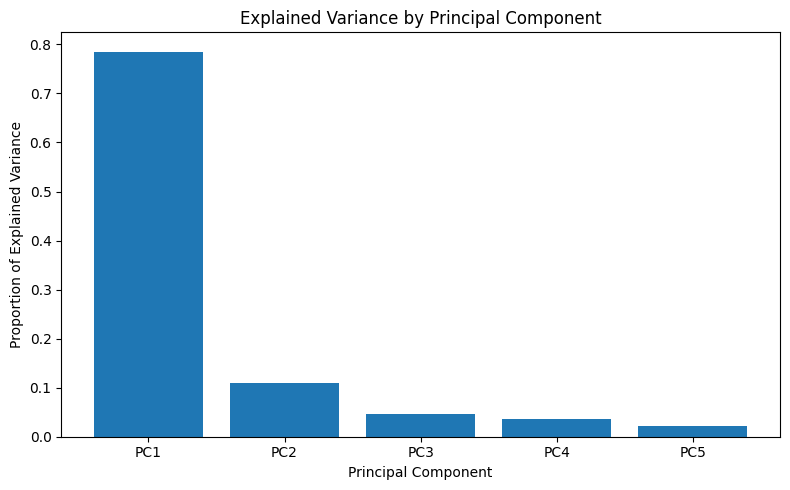

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    pc_columns,
    explained_variance
)

plt.xlabel("Principal Component")
plt.ylabel("Proportion of Explained Variance")
plt.title("Explained Variance by Principal Component")

plt.tight_layout()
plt.show()

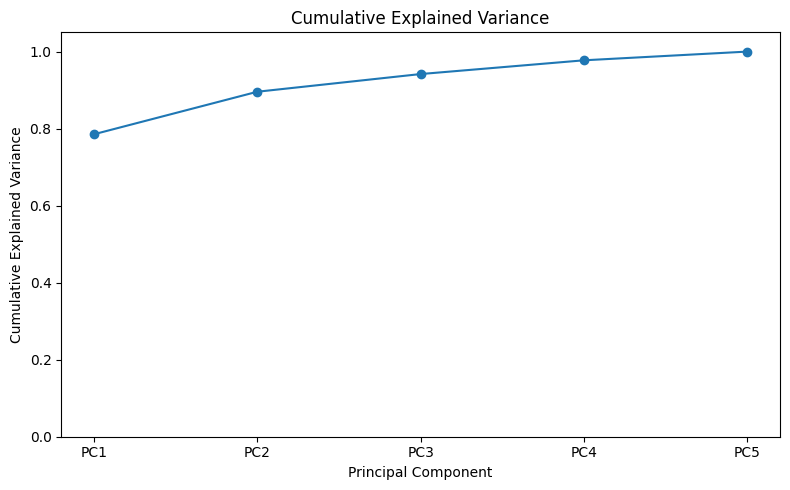

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    pc_columns,
    cumulative_variance,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")

plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()

In [ ]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=data.columns,
    columns=pc_columns
)

loadings

,PC1,PC2,PC3,PC4,PC5
S&P 500,0.476296,-0.094461,-0.229684,-0.423007,0.729746
NASDAQ,0.470379,-0.222508,-0.270988,-0.443005,-0.677898
Dow Jones,0.464009,-0.133407,-0.391724,0.783159,0.010553
Russell 2000,0.449054,-0.280795,0.841453,0.107027,-0.002556
Emerging Markets,0.367330,0.919197,0.110992,-0.004349,-0.088354


**Interpretation:**
PC1 has positive loadings across all five financial indices,
indicating that it captures a common market movement. PC2 is
dominated by Emerging Markets, suggesting that it captures a
distinct source of variation between Emerging Markets and the
U.S.-oriented indices.

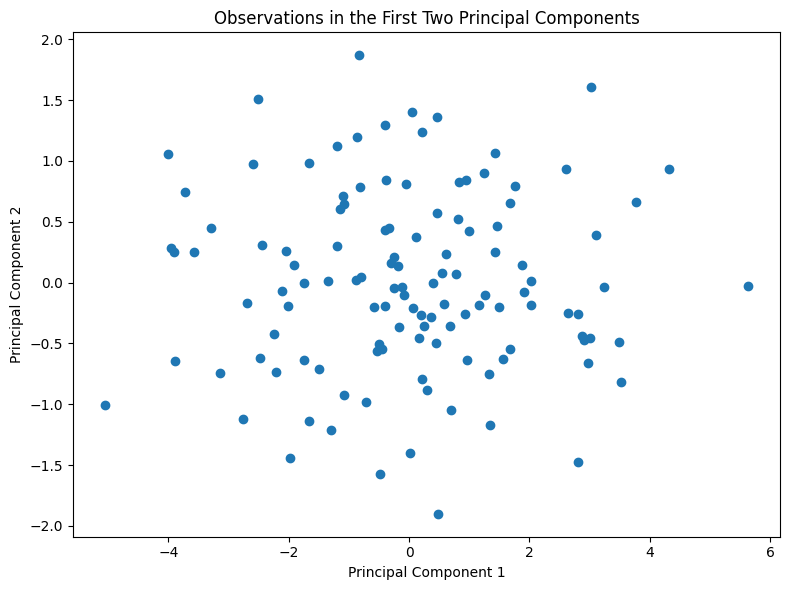

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    pc_data["PC1"],
    pc_data["PC2"]
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Observations in the First Two Principal Components")

plt.tight_layout()
plt.show()

In [ ]:
threshold = 0.90

n_components = np.argmax(cumulative_variance >= threshold) + 1

print(
    f"Number of components needed to explain at least "
    f"{threshold:.0%} of the variance: {n_components}"
)

Number of components needed to explain at least 90% of the variance: 3


In [ ]:
print(f"Variance explained by first 2 components: "
      f"{cumulative_variance[1]:.2%}")

print(f"Variance explained by first 3 components: "
      f"{cumulative_variance[2]:.2%}")

Variance explained by first 2 components: 89.58%
Variance explained by first 3 components: 94.17%


**Step 2 Category 2: k-means Clustering**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

In [ ]:
np.random.seed(42)
n = 300
returns = np.random.normal(0, 0.02, n)
volatility = np.random.normal(0.15, 0.05, n)
data = pd.DataFrame({'Returns': returns, 'Volatility': volatility})
print(data.head())
print(data.describe())

    Returns  Volatility
0  0.009934    0.108550
1 -0.002765    0.121991
2  0.012954    0.187365
3  0.030461    0.180519
4 -0.004683    0.148955
          Returns  Volatility
count  300.000000  300.000000
mean    -0.000111    0.148926
std      0.019684    0.048081
min     -0.064825    0.026418
25%     -0.013665    0.114780
50%      0.001184    0.149062
75%      0.012533    0.180817
max      0.077055    0.303944


In [ ]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)
print(scaled_data[:5])

[[ 5.11181814e-01 -8.41138965e-01]
 [-1.35072487e-01 -5.61128442e-01]
 [ 6.64837178e-01  8.00804712e-01]
 [ 1.55572267e+00  6.58178286e-01]
 [-2.32664344e-01  6.12896104e-04]]


In [ ]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
kmeans.fit(scaled_data)
data['Cluster'] = kmeans.labels_
print(data.head())
print("Cluster centers:")
print(kmeans.cluster_centers_)

    Returns  Volatility  Cluster
0  0.009934    0.108550        0
1 -0.002765    0.121991        0
2  0.012954    0.187365        1
3  0.030461    0.180519        1
4 -0.004683    0.148955        2
Cluster centers:
[[-0.04192666 -0.99300677]
 [ 0.90241764  0.44457335]
 [-0.91273976  0.64682322]]


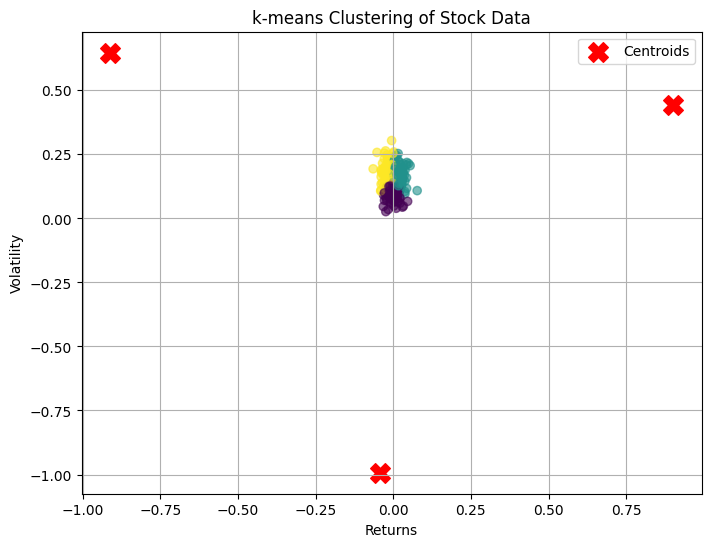

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(data['Returns'], data['Volatility'], c=data['Cluster'], cmap='viridis', alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Returns')
plt.ylabel('Volatility')
plt.title('k-means Clustering of Stock Data')
plt.legend()
plt.grid(True)
plt.show()

**Category 6: Support Vector Machine (SVM)**

In [ ]:
data['Target'] = (data['Returns'] > 0).astype(int)
X = data[['Returns', 'Volatility']]
y = data['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
scaler_svm = StandardScaler()
X_train_scaled = scaler_svm.fit_transform(X_train)
X_test_scaled = scaler_svm.transform(X_test)

In [ ]:
svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm.fit(X_train_scaled, y_train)
y_pred = svm.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9666666666666667
Confusion Matrix:
[[39  2]
 [ 1 48]]


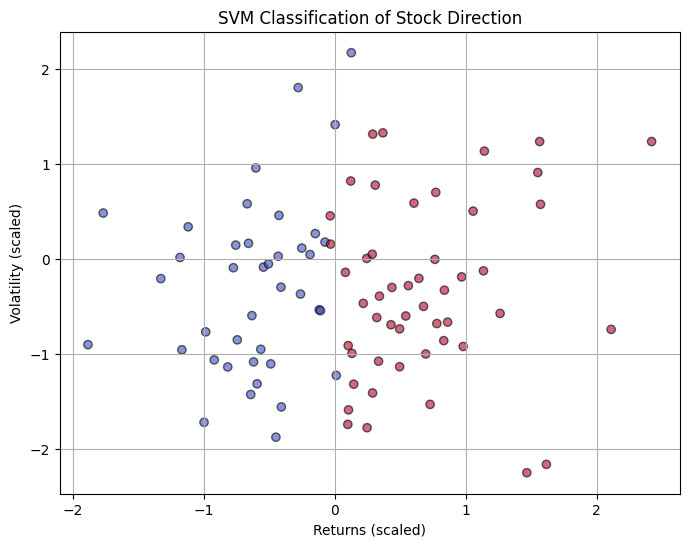

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X_test_scaled[:, 0], X_test_scaled[:, 1], c=y_pred, cmap='coolwarm', alpha=0.6, edgecolors='k')
plt.xlabel('Returns (scaled)')
plt.ylabel('Volatility (scaled)')
plt.title('SVM Classification of Stock Direction')
plt.grid(True)
plt.show()

**Category 5 — LDA Computation**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
np.random.seed(42)

n = 500

# Generate financial indicators
returns = np.random.normal(0, 0.03, n)
volatility = np.random.uniform(0.01, 0.08, n)
momentum = np.random.normal(0, 0.04, n)

# Create a score associated with the next-period return direction
score = (
    0.8 * returns
    + 0.6 * momentum
    - 0.3 * volatility
    + np.random.normal(0, 0.015, n)
)

# Classify observations into two classes
market_direction = np.where(score > 0, 1, 0)

data_lda = pd.DataFrame({
    "Historical Return": returns,
    "Volatility": volatility,
    "Momentum": momentum,
    "Market Direction": market_direction
})

data_lda.head()

,Historical Return,Volatility,Momentum,Market Direction
0,0.014901,0.055214,-0.006685,0
1,-0.004148,0.049954,0.005869,0
2,0.019431,0.034927,0.048260,1
3,0.045691,0.079056,-0.032677,0
4,-0.007025,0.052404,0.014747,0


In [ ]:
data_lda["Market Direction"].value_counts()

,count
Market Direction,
0,302
1,198


In [ ]:
X = data_lda[
    ["Historical Return", "Volatility", "Momentum"]
]

y = data_lda["Market Direction"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 400
Testing observations: 100


In [ ]:
lda = LinearDiscriminantAnalysis()

lda.fit(X_train, y_train)

LinearDiscriminantAnalysis()

In [ ]:
y_pred = lda.predict(X_test)

predictions = pd.DataFrame({
    "Actual Class": y_test.to_numpy(),
    "Predicted Class": y_pred
})

predictions.head(10)

,Actual Class,Predicted Class
0,0,0
1,1,1
2,0,0
3,0,0
4,1,1
5,0,0
6,1,1
7,0,0
8,0,0
9,0,0


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.2%}")

Test Accuracy: 84.00%


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[55  5]
 [11 29]]


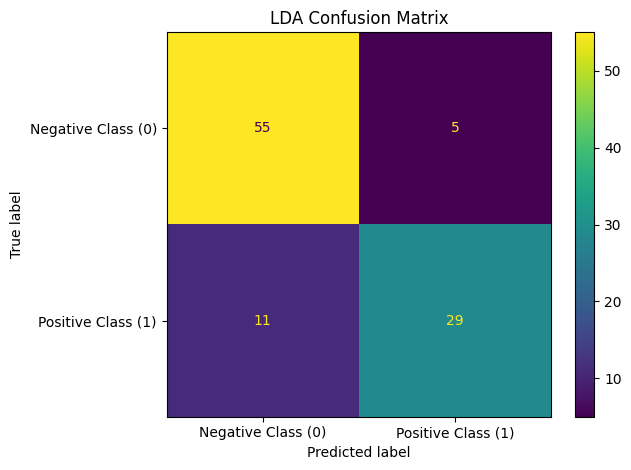

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative Class (0)", "Positive Class (1)"]
)

disp.plot()
plt.title("LDA Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative Class (0)", "Positive Class (1)"],
    zero_division=0
))

                    precision    recall  f1-score   support

Negative Class (0)       0.83      0.92      0.87        60
Positive Class (1)       0.85      0.72      0.78        40

          accuracy                           0.84       100
         macro avg       0.84      0.82      0.83       100
      weighted avg       0.84      0.84      0.84       100



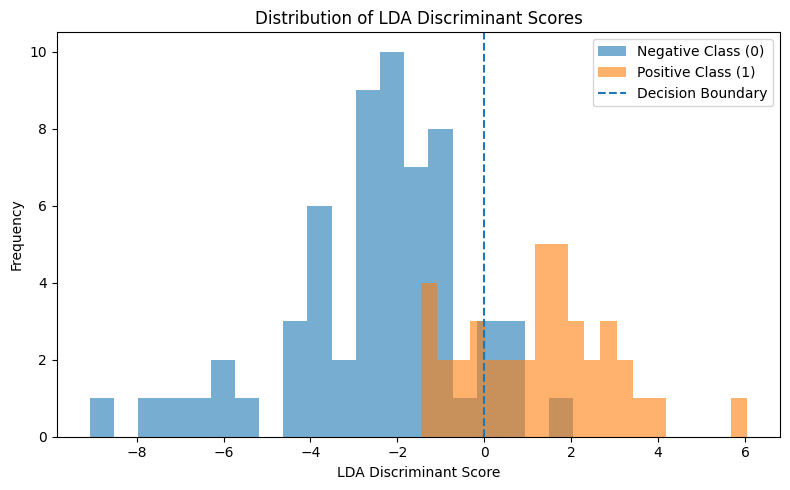

In [ ]:
discriminant_scores = lda.decision_function(X_test)

plt.figure(figsize=(8, 5))

plt.hist(
    discriminant_scores[y_test.to_numpy() == 0],
    bins=20,
    alpha=0.6,
    label="Negative Class (0)"
)

plt.hist(
    discriminant_scores[y_test.to_numpy() == 1],
    bins=20,
    alpha=0.6,
    label="Positive Class (1)"
)

plt.axvline(0, linestyle="--", label="Decision Boundary")
plt.xlabel("LDA Discriminant Score")
plt.ylabel("Frequency")
plt.title("Distribution of LDA Discriminant Scores")
plt.legend()
plt.tight_layout()
plt.show()

The LDA model achieved 84% test accuracy. Recall was higher for the negative class (92%) than the positive class (72%), indicating that the model identified negative-class observations more effectively. These results are based on synthetic data and do not establish real-market predictive performance.

In [ ]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "LDA Coefficient": lda.coef_[0]
})

coefficients

,Feature,LDA Coefficient
0,Historical Return,58.394974
1,Volatility,-20.124677
2,Momentum,54.407441


Historical Return (58.395) and Momentum (54.407) have positive coefficients, while Volatility (-20.125) has a negative coefficient. Thus, higher returns and momentum increase the score toward class 1, while higher volatility decreases it, holding other features constant. These relationships reflect the synthetic dataset.

In [ ]:
print("Intercept:", lda.intercept_[0])

Intercept: -0.13237915017417068


**Category 7: Neural Networks**

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:

np.random.seed(42)

n = 500

# Generate synthetic financial indicators
returns = np.random.normal(0, 0.03, n)
volatility = np.random.uniform(0.01, 0.08, n)
momentum = np.random.normal(0, 0.04, n)

# Generate a score associated with market direction
score = (
    0.8 * returns
    + 0.6 * momentum
    - 0.3 * volatility
    + np.random.normal(0, 0.015, n)
)

# Classify market direction
market_direction = np.where(score > 0, 1, 0)

data_nn = pd.DataFrame({
    "Historical Return": returns,
    "Volatility": volatility,
    "Momentum": momentum,
    "Market Direction": market_direction
})

data_nn.head()

,Historical Return,Volatility,Momentum,Market Direction
0,0.014901,0.055214,-0.006685,0
1,-0.004148,0.049954,0.005869,0
2,0.019431,0.034927,0.048260,1
3,0.045691,0.079056,-0.032677,0
4,-0.007025,0.052404,0.014747,0


In [ ]:

X = data_nn[["Historical Return", "Volatility", "Momentum"]]
y = data_nn["Market Direction"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training class distribution:")
print(y_train.value_counts())

Training observations: 400
Testing observations: 100
Training class distribution:
Market Direction
0    242
1    158
Name: count, dtype: int64


In [ ]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (400, 3)
Testing data shape: (100, 3)


In [ ]:

nn_model = MLPClassifier(
    hidden_layer_sizes=(10, 5),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42
)

nn_model.fit(X_train_scaled, y_train)

print("Neural network training completed.")
print("Number of training iterations:", nn_model.n_iter_)

Neural network training completed.
Number of training iterations: 247


In [ ]:

y_pred = nn_model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=[
    "Negative Class (0)",
    "Positive Class (1)"
]))

Test Accuracy: 84.00%

Classification Report:
                    precision    recall  f1-score   support

Negative Class (0)       0.87      0.87      0.87        60
Positive Class (1)       0.80      0.80      0.80        40

          accuracy                           0.84       100
         macro avg       0.83      0.83      0.83       100
      weighted avg       0.84      0.84      0.84       100



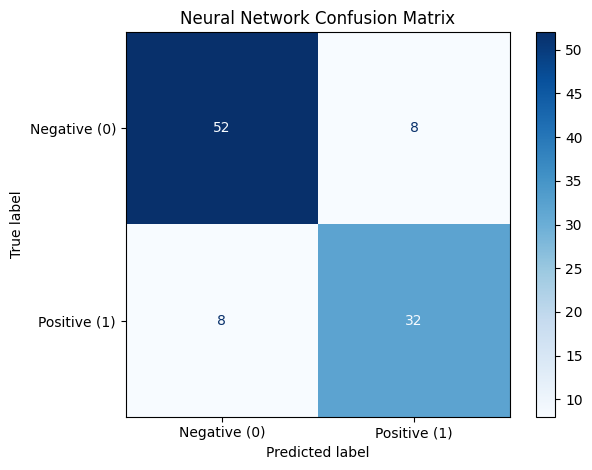

In [ ]:

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative (0)", "Positive (1)"]
)

disp.plot(cmap="Blues")
plt.title("Neural Network Confusion Matrix")
plt.tight_layout()
plt.show()

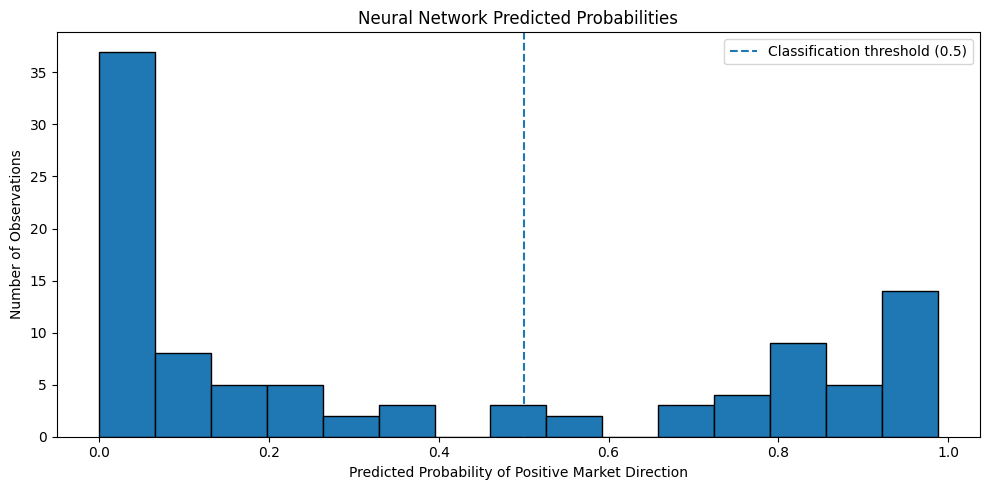

In [ ]:

positive_probabilities = nn_model.predict_proba(X_test_scaled)[:, 1]

plt.figure(figsize=(10, 5))
plt.hist(positive_probabilities, bins=15, edgecolor="black")
plt.axvline(0.5, linestyle="--", label="Classification threshold (0.5)")

plt.title("Neural Network Predicted Probabilities")
plt.xlabel("Predicted Probability of Positive Market Direction")
plt.ylabel("Number of Observations")
plt.legend()
plt.tight_layout()
plt.show()

The neural network was trained to classify market direction using historical returns, volatility, and momentum. Its performance was evaluated on a separate test dataset using accuracy, precision, recall, F1-score, and a confusion matrix. The predicted-probability distribution provides additional insight into the model's classification decisions.

The results demonstrate how a neural network can learn relationships between financial indicators and market direction. However, the dataset is synthetic, so the findings do not establish predictive performance in real financial markets.